# Validation of 3D outputs

This notebooks uses the [modelskill](https://dhi.github.io/modelskill/) package for validating the 3D model output data.

Note, that this notebook has been prepared using an alpha-release of modelskill (1.4.0a3). 3D validation has not been implemented in prior versions, so at least 1.4.0a3 is required, but the code might need slight modification for future releases.

In [1]:
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd

In [2]:
# mr_fldr = "../output_sample/"
mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

mr_fn = "3D_2023_2025_hrly.dfsu" # model result file name

obs_fldr = "../observations/" 

# Temperature and salinity

Load the in-situ measurement data of temperature and salinity.

Note, that this section only works for the full dataset (not the sample), which can be downloaded from Zenodo, since the observations are very sparse temporally.

In [3]:
# Only validate over the stations that have T/S profile data
ts_stations = ["FRB9070", "KBH431", "KBK1728"]
stations = (
    pd.read_csv("../observations/stations.csv")
    .set_index("Station", drop=False)
    .loc[ts_stations]
)
stations


,Station,Longitude,Latitude,Longitude_original,Latitude_original
Station,,,,,
FRB9070,FRB9070,12.638,55.924,NaN,NaN
KBH431,KBH431,12.750,55.867,NaN,NaN
KBK1728,KBK1728,12.714,55.537,NaN,NaN


In [4]:
def validate_ts_station(station_name, xpos, ypos, z_ts=-24):
    quants = ['T', 'S']
    names = {'T': 'Temperature', 'S': 'Salinity'}
    units = {'T': '°C', 'S': 'PSU'}

    for q in quants:
        vo = ms.VerticalObservation(
            f"{obs_fldr}{station_name}_{q}_All.dfs0",
            item=names[q].lower(),
            z_item="z",
            x=xpos,
            y=ypos,
            quantity=ms.Quantity(names[q], units[q]),
        )
        mr = ms.DfsuModelResult(f"{mr_fldr}{mr_fn}", item=names[q], name="MIKE3")
        ax = ms.plotting.spatial_overview(vo, mr)
        try:
            cmp = ms.match(vo, mr)
            cmp.skill()

            fig, ax = plt.subplots(2, 3, figsize=(18, 12))
            _ = cmp.plot(ax=ax[0,0])
            _ = cmp.plot.hist(ax=ax[0,1])
            _ = cmp.plot.kde(ax=ax[0,2])
            _ = cmp.plot.box(ax=ax[1,0])
            _ = cmp.plot.qq(ax=ax[1,1])
            _ = cmp.sel(z=z_ts).plot.timeseries(ax=ax[1,2])
            plt.tight_layout()
            if save_png: plt.savefig(f"../figures/{station_name}_{q}_comparison.png", dpi=300, bbox_inches='tight')
            plt.show()

            sk = cmp.vertical.skill(bins=[-25, -20, -15, -10, -5, 0])
            print(sk.to_dataframe())

            ax = cmp.vertical.plot.hovmoller(figsize=(16, 5), obs_marker_size=100)
            plt.tight_layout()
            if save_png: plt.savefig(f"../figures/{station_name}_{q}_hovmoller.png", dpi=300, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error processing {station_name} for {q}: {e}")


## FRB station
Load the data belonging to the FRB station and use modelskill to compare to the model data

In [5]:
station_name = "FRB9070"
xpos = stations.loc[stations['Station'] == station_name, 'Longitude'].values[0]
ypos = stations.loc[stations['Station'] == station_name, 'Latitude'].values[0]

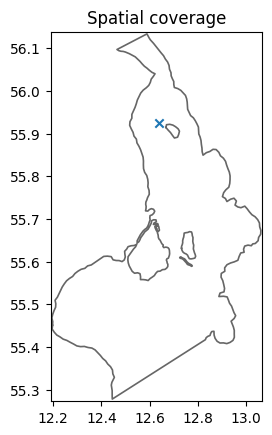

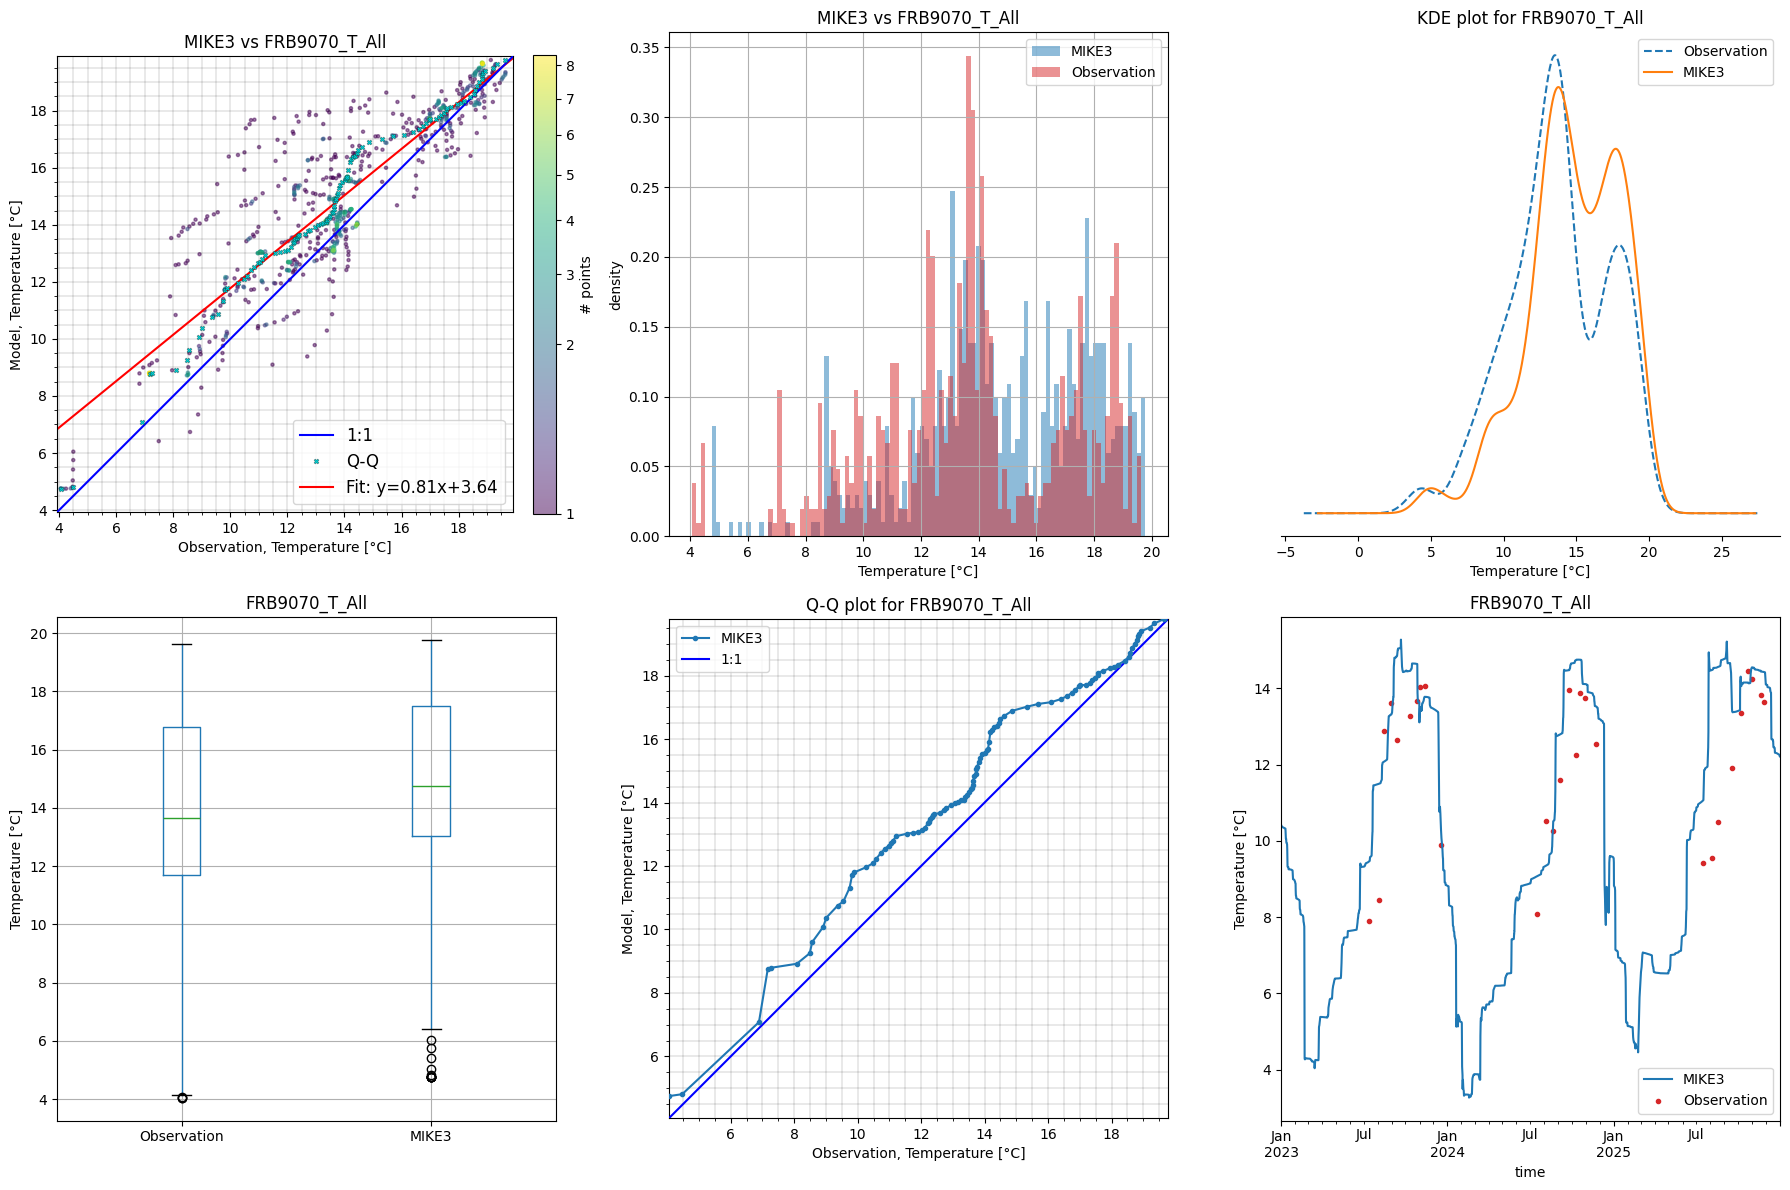

                bias      rmse     urmse       mae        cc        si  \
z                                                                        
(-25, -20]  2.047314  3.080603  2.301873  2.319804  0.227534  0.187557   
(-20, -15]  1.307817  2.309131  1.903076  1.774570  0.595346  0.142813   
(-15, -10]  0.652531  1.260484  1.078436  1.030196  0.946322  0.075664   
(-10, -5]   0.618802  1.038251  0.833696  0.838428  0.983566  0.057677   
(-5, 0]     0.738566  1.009537  0.688248  0.837407  0.990409  0.047932   

                  r2    n  
z                          
(-25, -20] -1.608652  140  
(-20, -15] -0.667463  140  
(-15, -10]  0.857063  140  
(-10, -5]   0.939620  140  
(-5, 0]     0.948325  112  


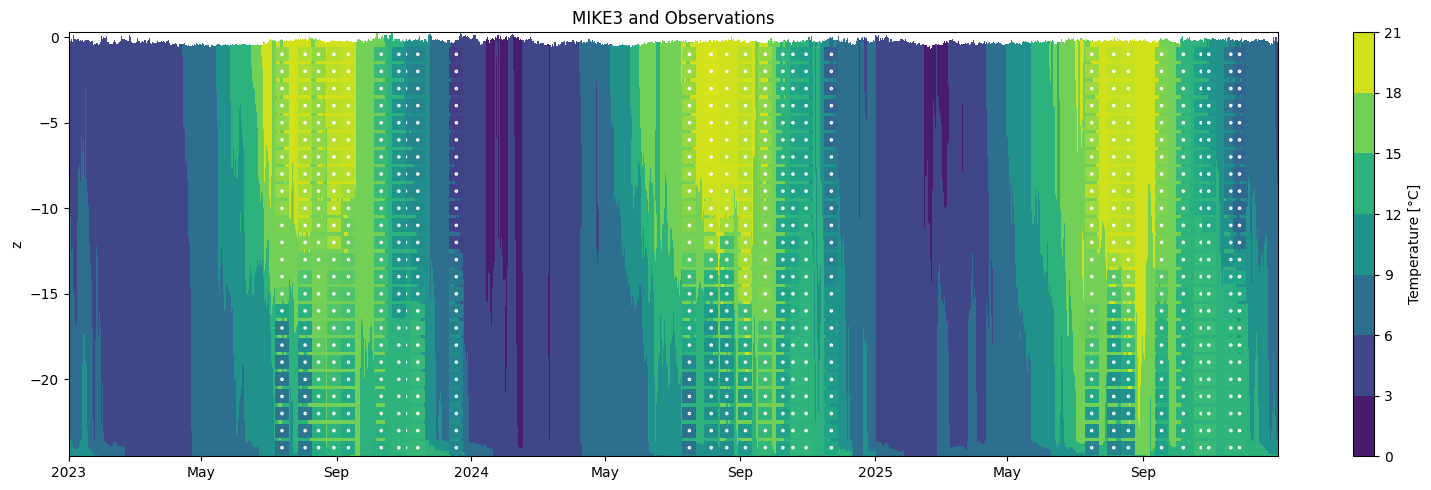

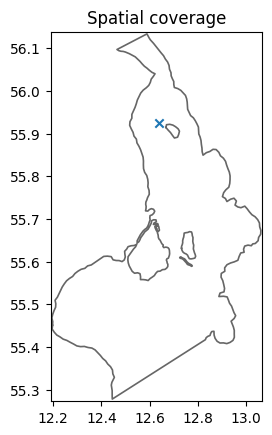

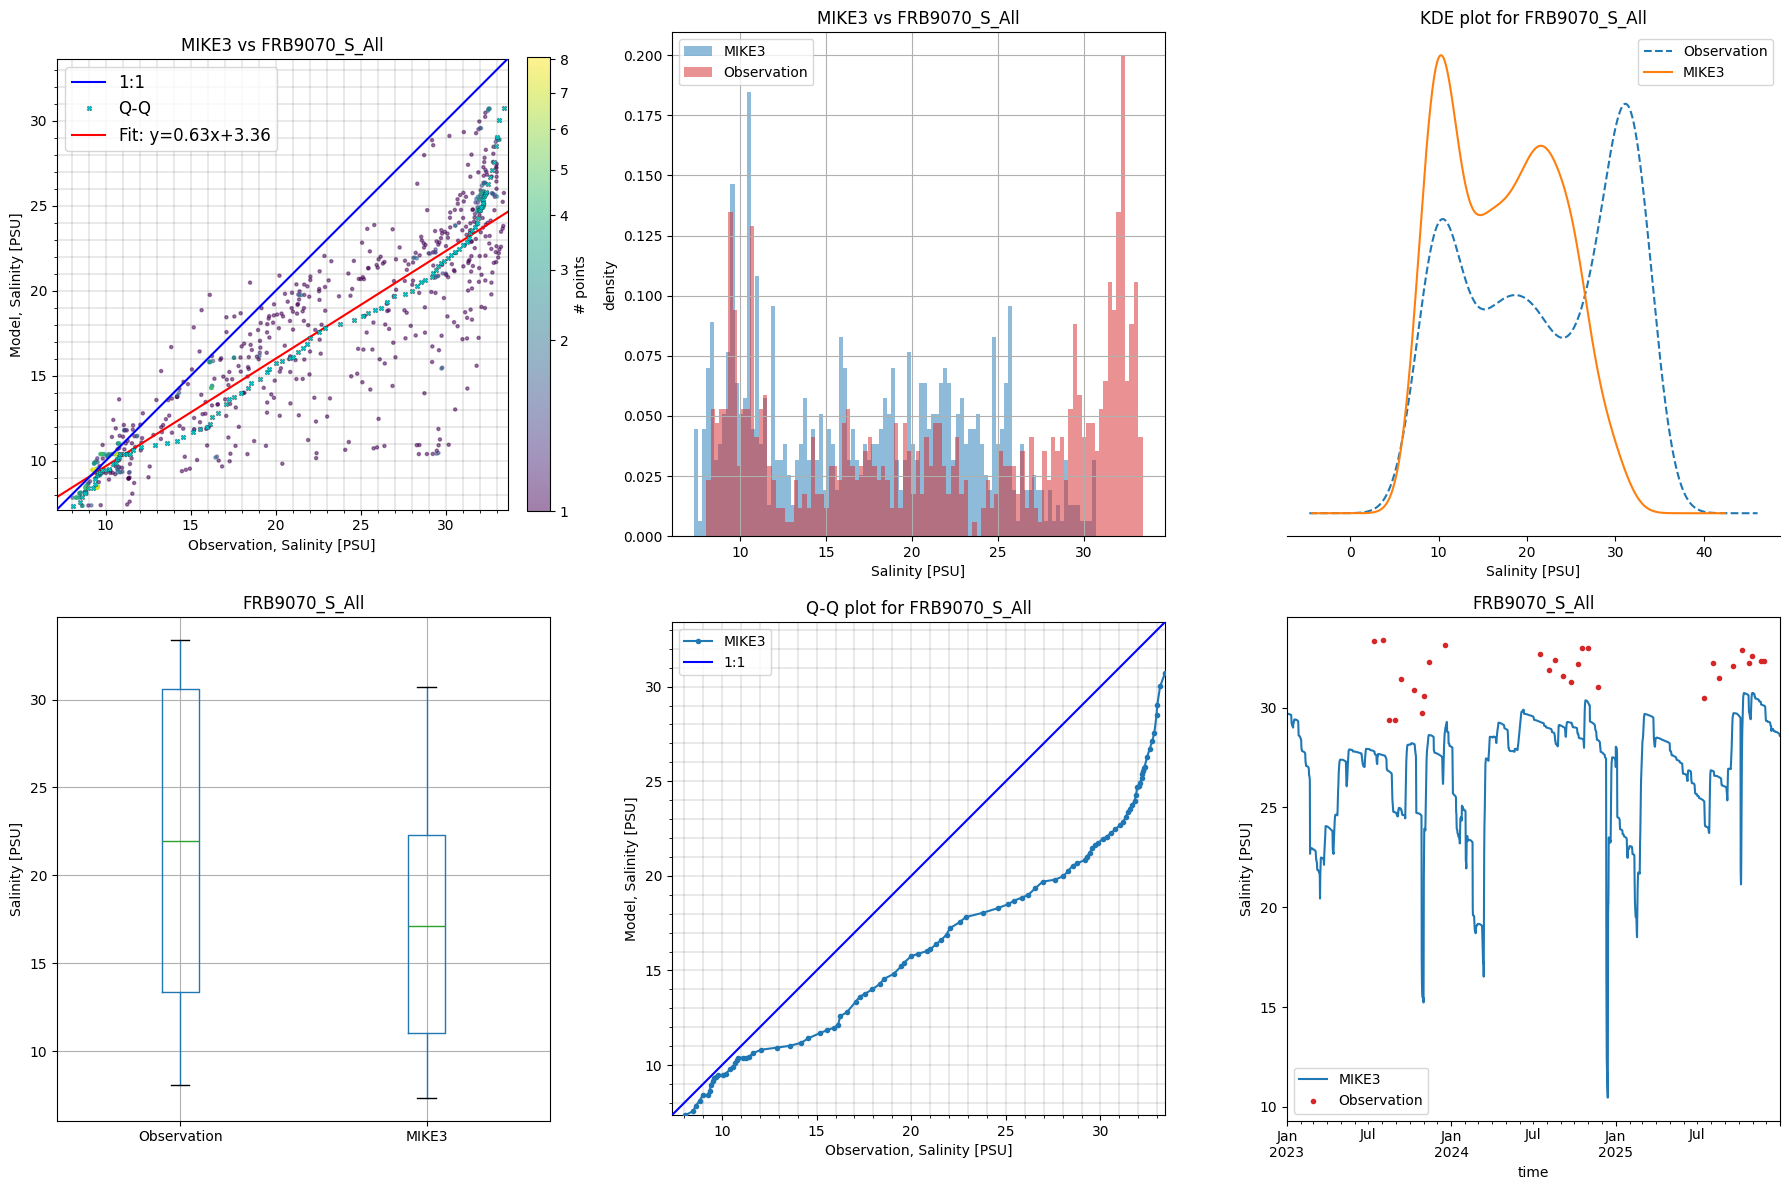

                bias      rmse     urmse       mae        cc        si  \
z                                                                        
(-25, -20] -7.914941  8.736268  3.698119  7.914941  0.627782  0.117525   
(-20, -15] -7.984328  8.875765  3.876817  7.984328  0.603185  0.133764   
(-15, -10] -4.322942  5.782771  3.840913  4.557737  0.753957  0.185069   
(-10, -5]  -1.623998  2.679135  2.130820  1.880168  0.877782  0.150047   
(-5, 0]    -0.796711  1.531523  1.307982  1.077610  0.927249  0.108455   

                   r2    n  
z                           
(-25, -20] -35.813901  140  
(-20, -15]  -5.028551  140  
(-15, -10]   0.021229  140  
(-10, -5]    0.631302  140  
(-5, 0]      0.798283  112  


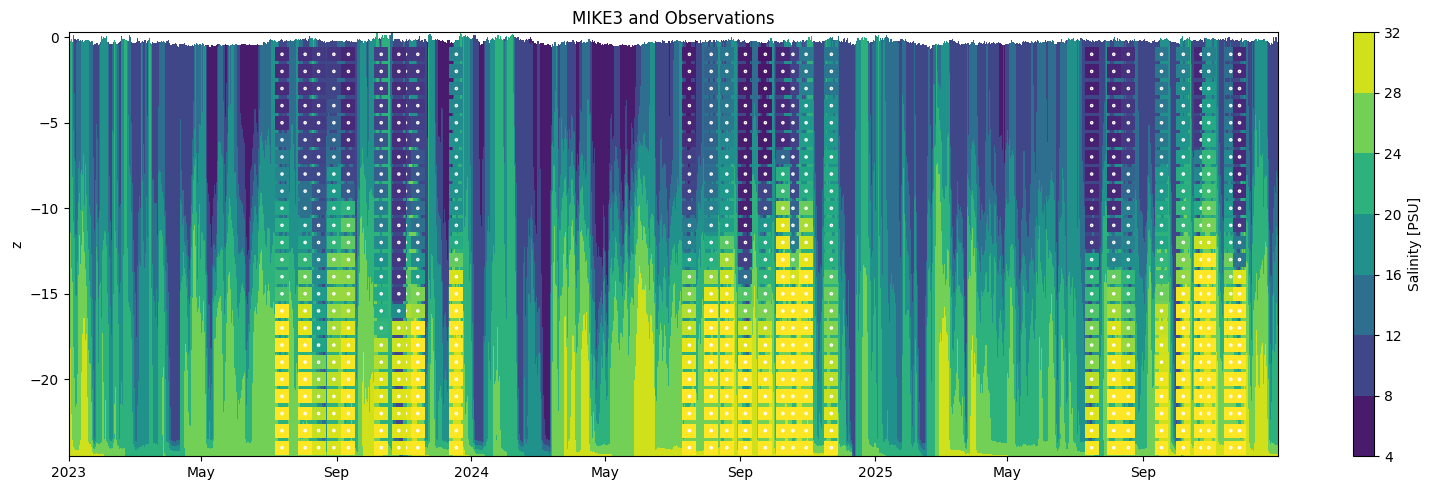

In [6]:
validate_ts_station(station_name, xpos, ypos, z_ts=-24)

The model captures temperature very well, but is more challenged on modelling the salinity, which is generally underpredicted. This is information that could be used to calibrate the model further, but we remind the user that the current model setup has not been calibrated to full capacity, and should therefore only be used for educational, benchmarking, and research purposes only, NOT operational setups.

## KBH station

In [7]:
station_name = "KBH431"
xpos = stations.loc[stations['Station'] == station_name, 'Longitude'].values[0]
ypos = stations.loc[stations['Station'] == station_name, 'Latitude'].values[0]

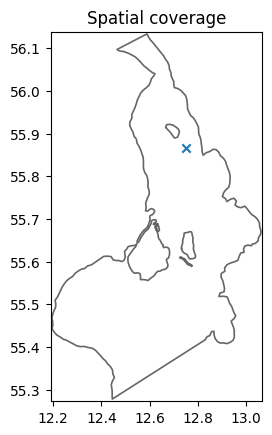

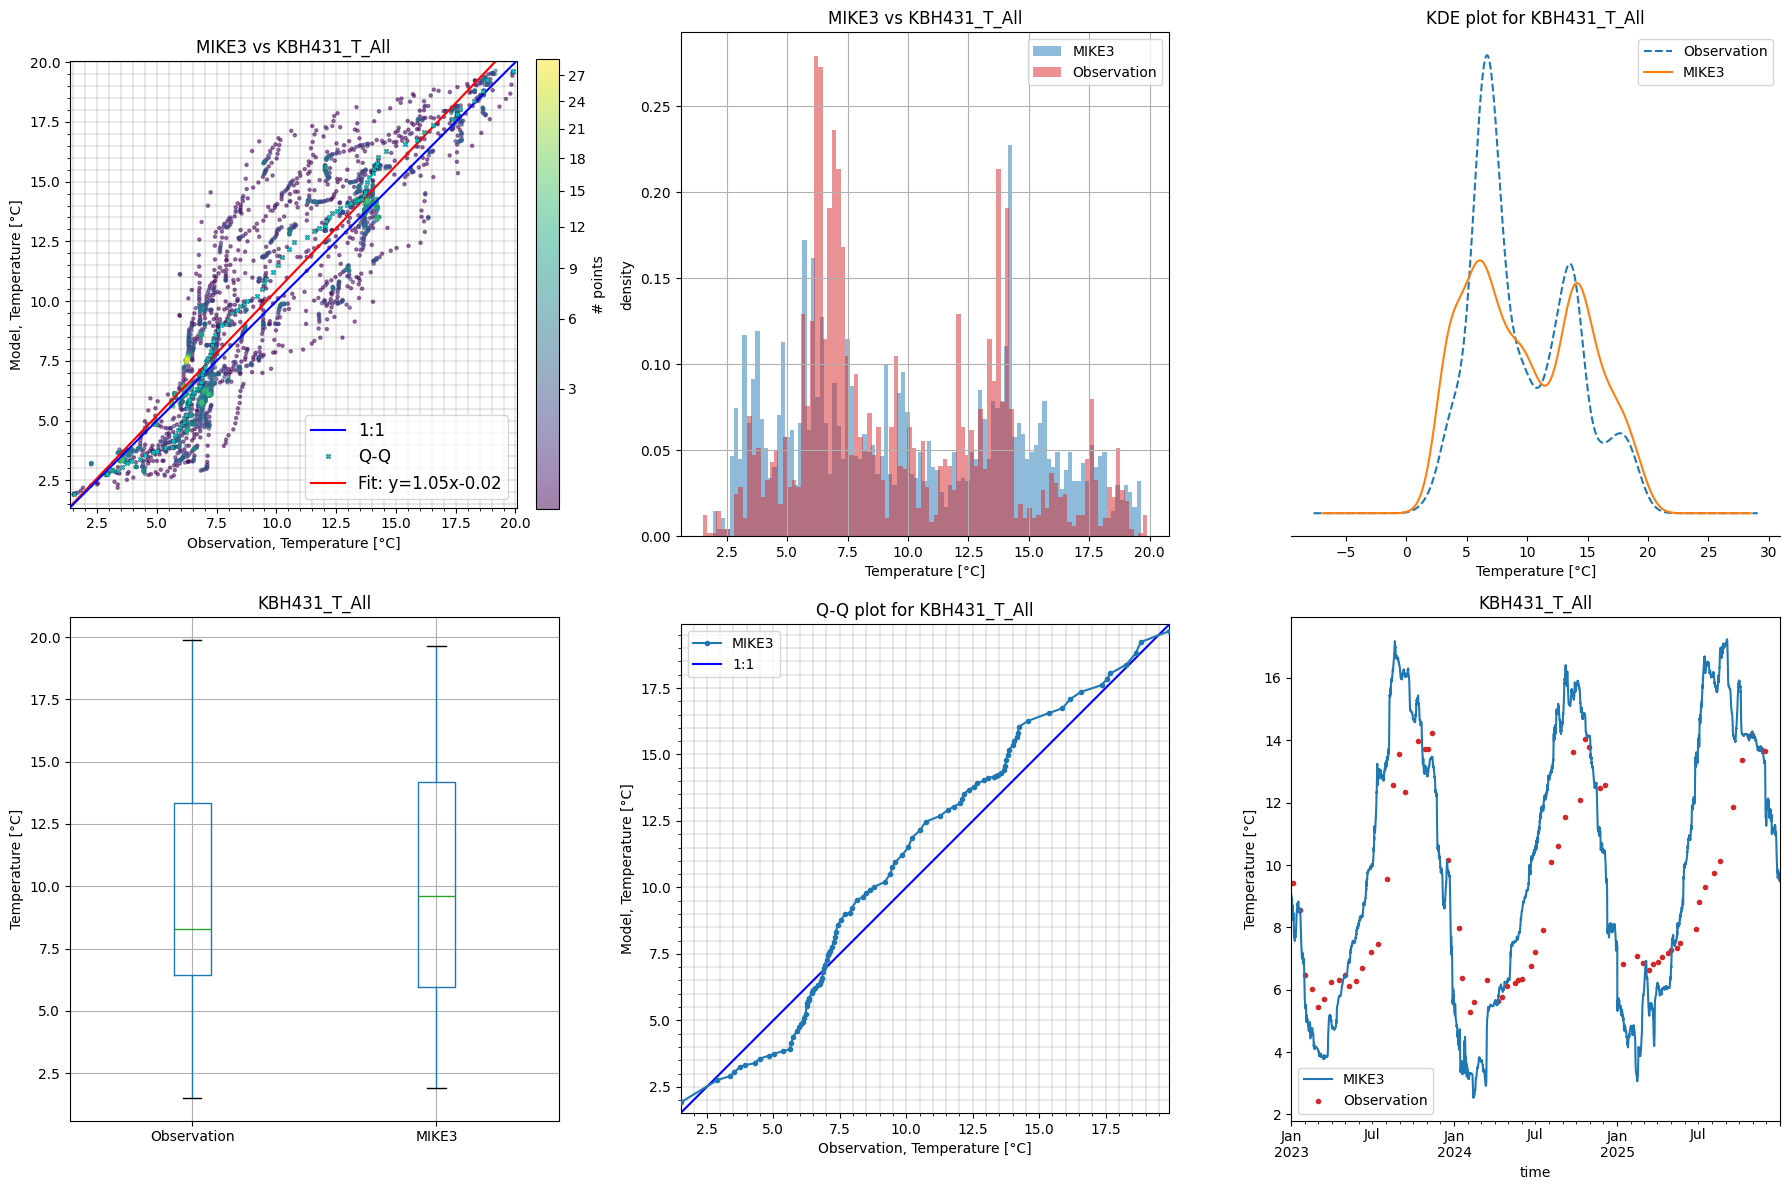

                bias      rmse     urmse       mae        cc        si  \
z                                                                        
(-25, -20]  0.762360  2.563737  2.447765  1.971655  0.846168  0.268423   
(-20, -15]  0.529845  2.123810  2.056656  1.652692  0.912318  0.217018   
(-15, -10]  0.145474  1.553881  1.547056  1.148235  0.957738  0.152277   
(-10, -5]  -0.204763  1.265749  1.249077  0.971346  0.975057  0.115959   
(-5, 0]    -0.146574  1.210617  1.201711  0.921660  0.978163  0.111149   

                  r2    n  
z                          
(-25, -20]  0.334456  340  
(-20, -15]  0.678122  340  
(-15, -10]  0.894158  340  
(-10, -5]   0.946778  340  
(-5, 0]     0.953878  272  


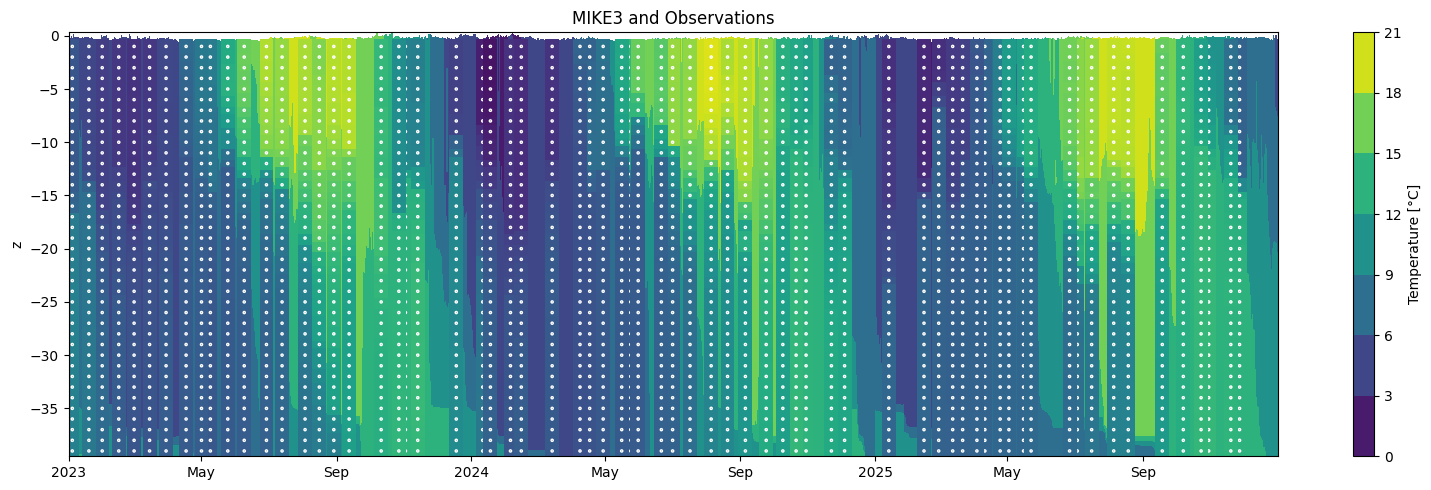

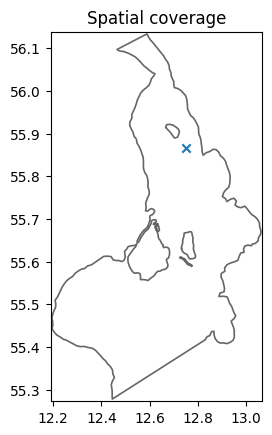

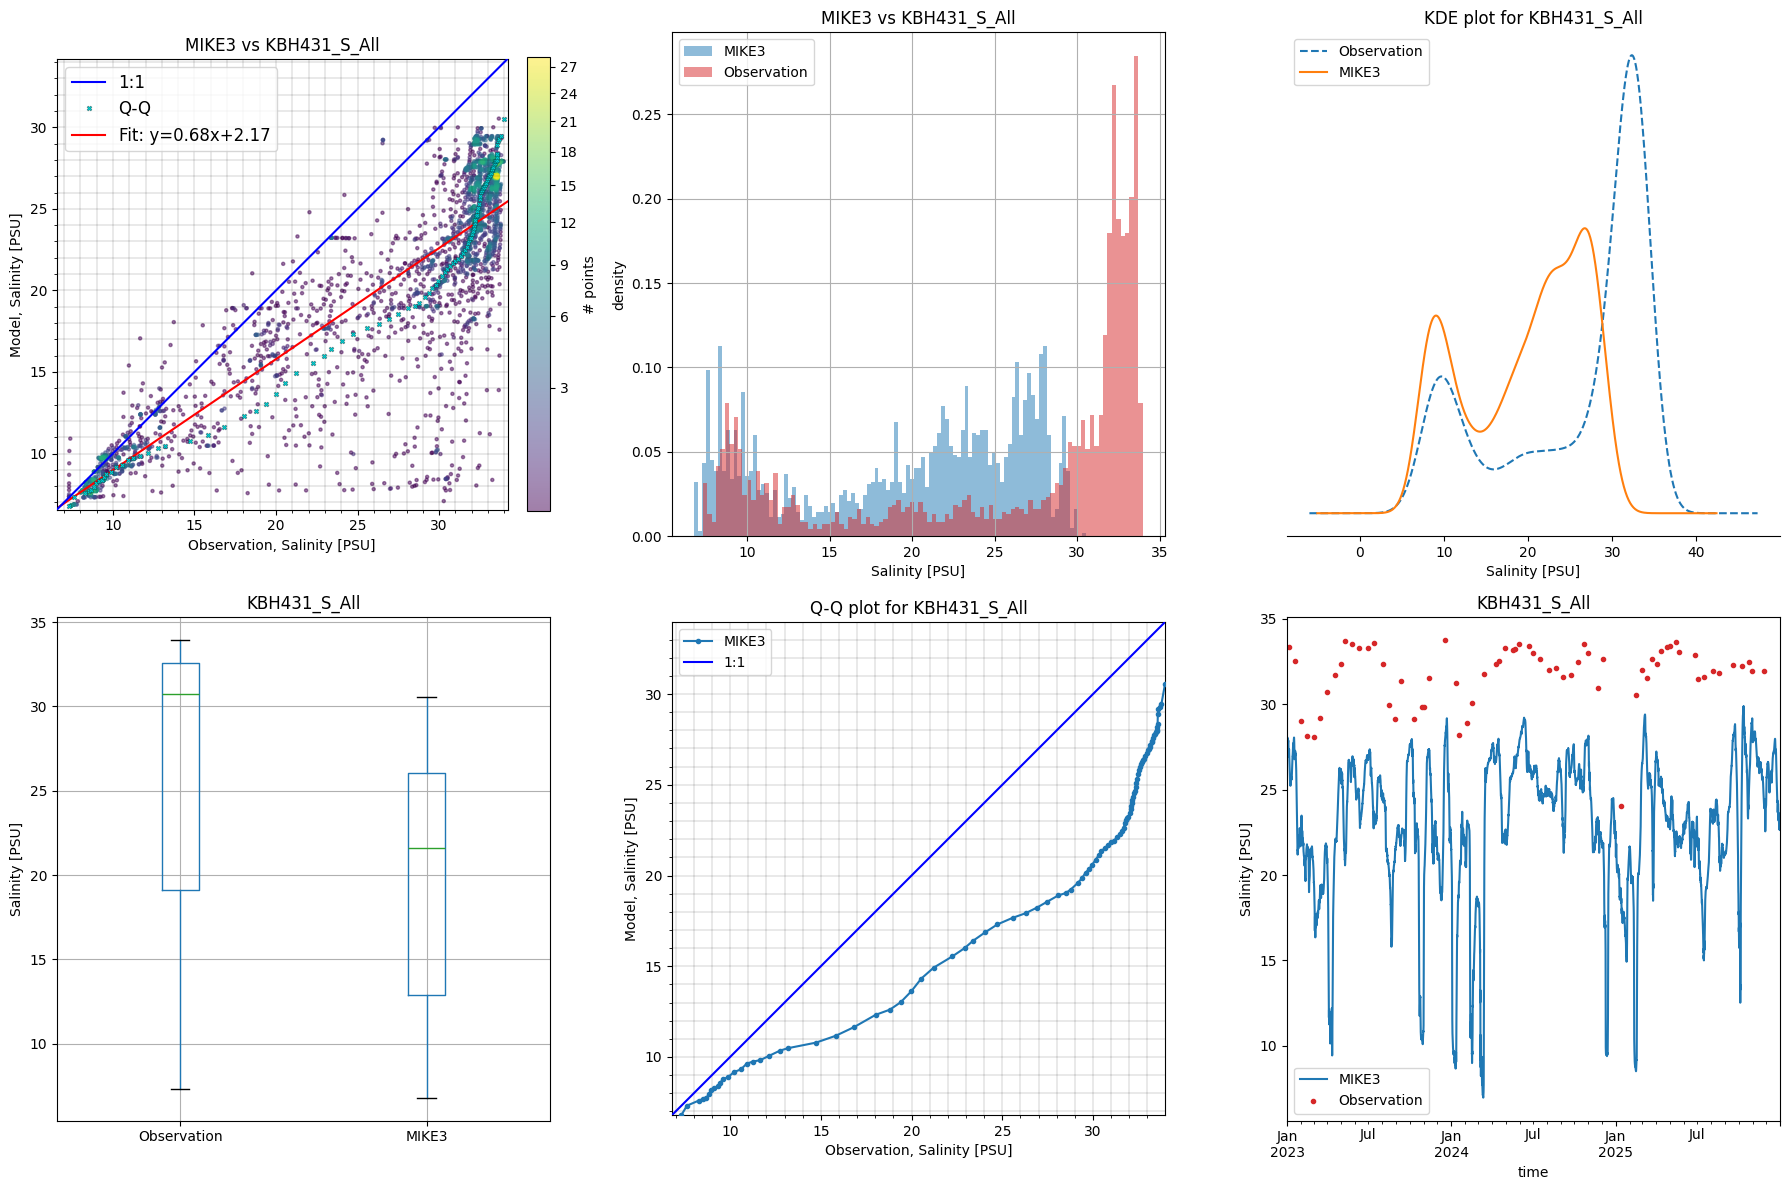

                bias       rmse     urmse       mae        cc        si  \
z                                                                         
(-25, -20] -9.052847   9.886985  3.974724  9.052847  0.506395  0.126937   
(-20, -15] -9.465187  10.483882  4.507995  9.467423  0.558317  0.154230   
(-15, -10] -5.699207   7.781327  5.297932  5.998725  0.721277  0.252026   
(-10, -5]  -1.650794   2.725747  2.169003  1.822576  0.913170  0.162803   
(-5, 0]    -1.061708   1.798508  1.451691  1.257705  0.936518  0.123191   

                   r2    n  
z                           
(-25, -20] -17.885538  335  
(-20, -15]  -4.797830  335  
(-15, -10]  -0.039287  335  
(-10, -5]    0.716728  335  
(-5, 0]      0.804339  268  


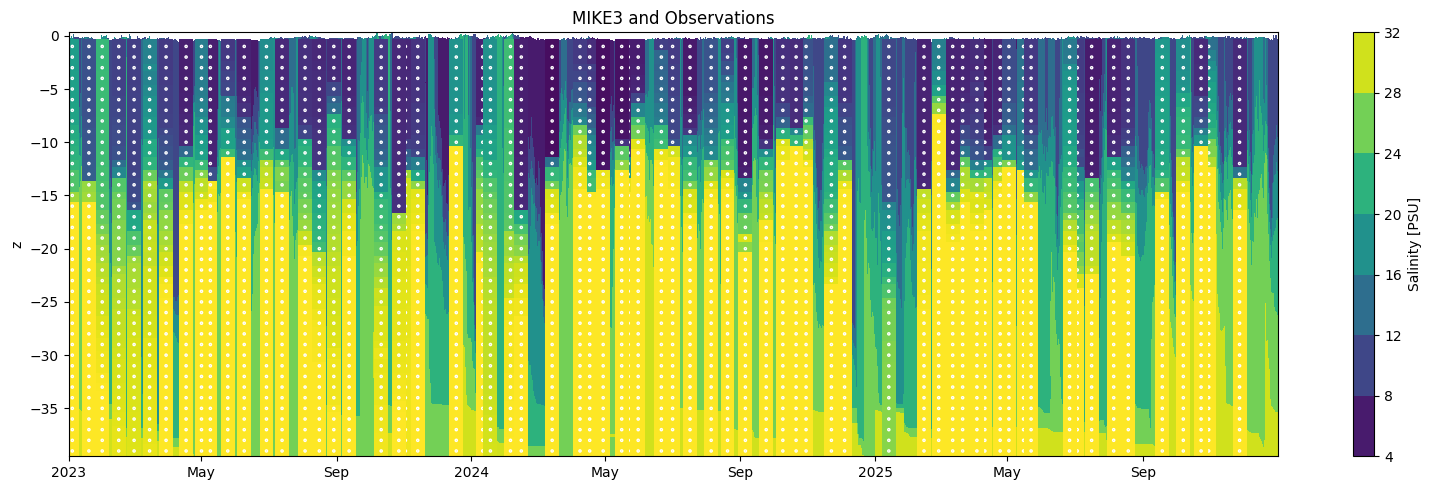

In [8]:
validate_ts_station(station_name, xpos, ypos, z_ts=-24)

The model captures temperature very well, but is more challenged on modelling the salinity, which is generally underpredicted. This is information that could be used to calibrate the model further, but we remind the user that the current model setup has not been calibrated to full capacity, and should therefore only be used for educational, benchmarking, and research purposes only, NOT operational setups.

## KBH station 2

In [9]:
station_name = "KBK1728"
xpos = stations.loc[stations['Station'] == station_name, 'Longitude'].values[0]
ypos = stations.loc[stations['Station'] == station_name, 'Latitude'].values[0]

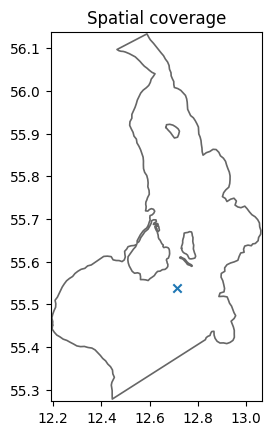

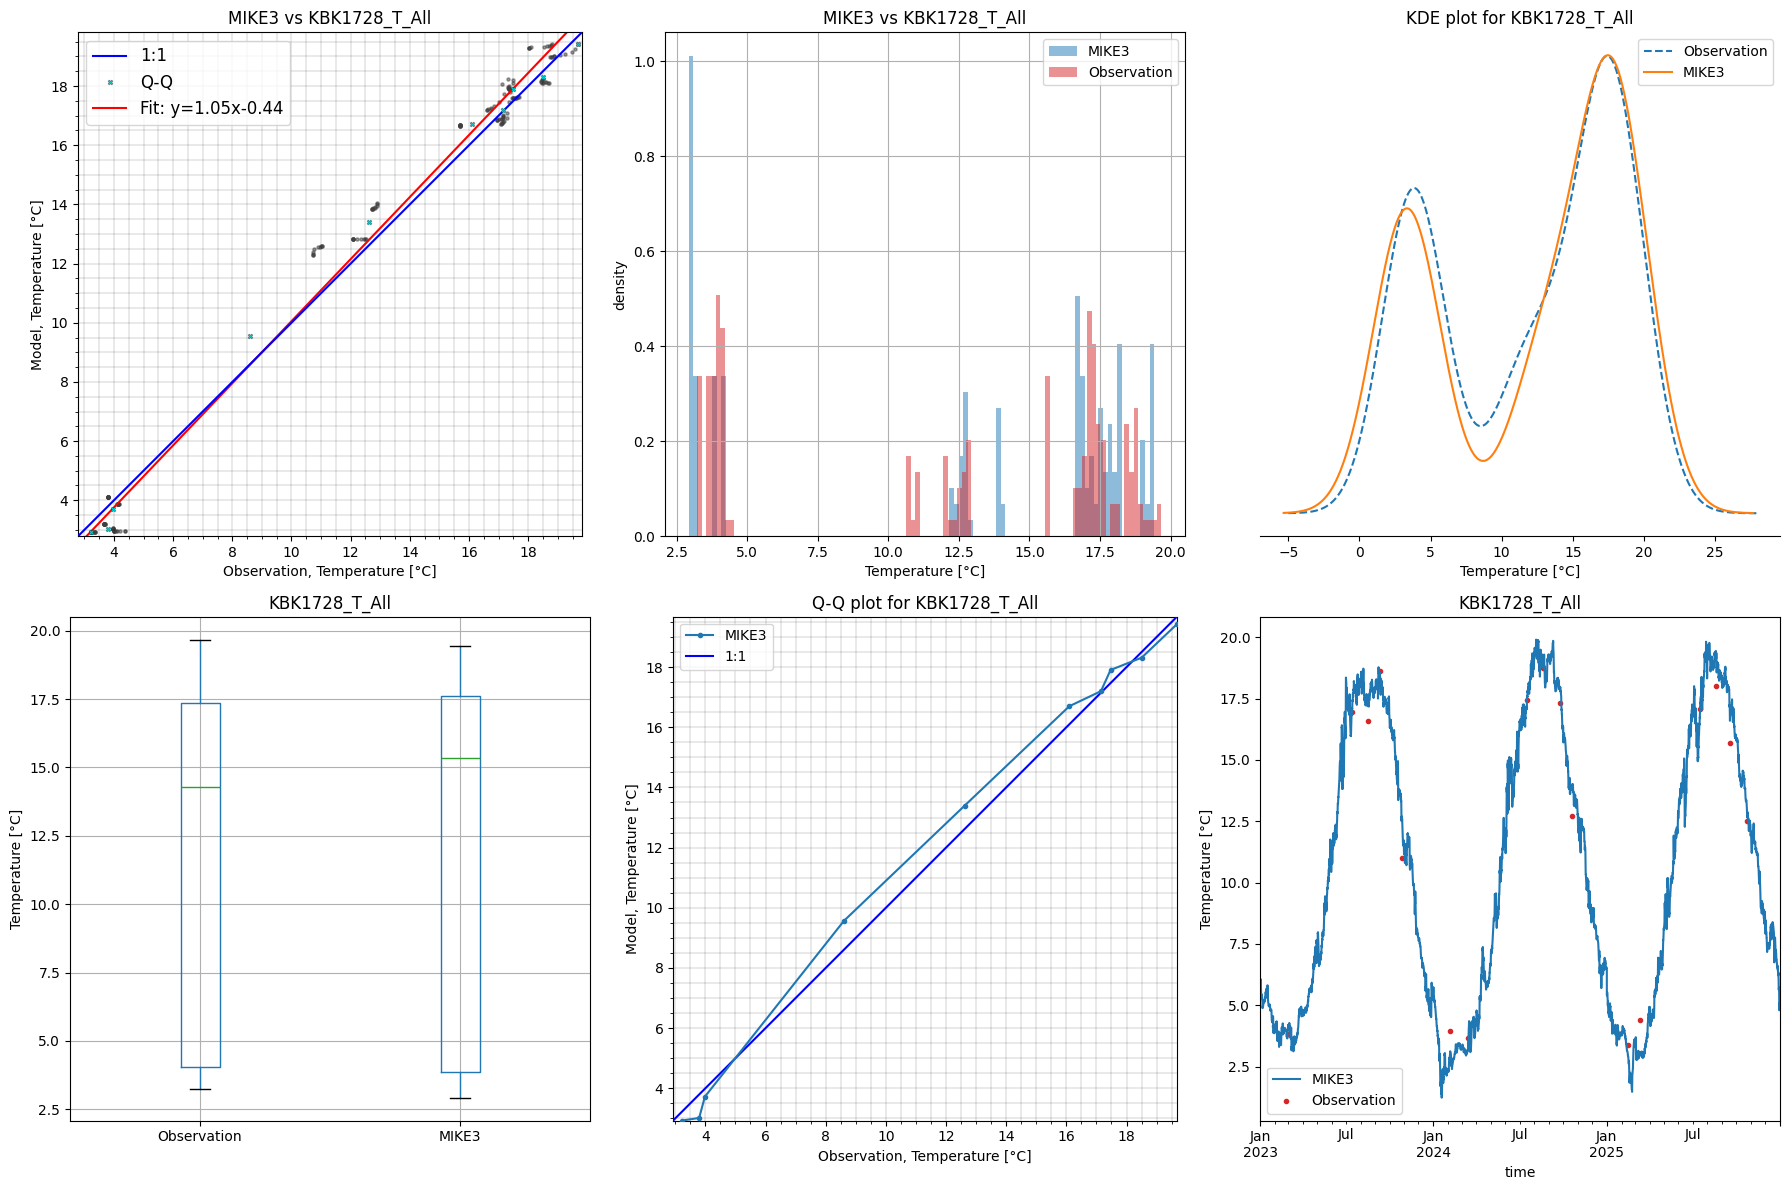

                bias      rmse     urmse       mae        cc        si  \
z                                                                        
(-25, -20]       NaN       NaN       NaN       NaN       NaN       NaN   
(-20, -15]       NaN       NaN       NaN       NaN       NaN       NaN   
(-15, -10]  0.145011  0.785025  0.771516  0.645368  0.994444  0.064284   
(-10, -5]   0.144960  0.750788  0.736660  0.617914  0.994698  0.061329   
(-5, 0]     0.164606  0.719619  0.700541  0.595235  0.995168  0.057953   

                  r2     n  
z                           
(-25, -20]       NaN   NaN  
(-20, -15]       NaN   NaN  
(-15, -10]  0.983326  18.0  
(-10, -5]   0.985033  90.0  
(-5, 0]     0.986793  72.0  


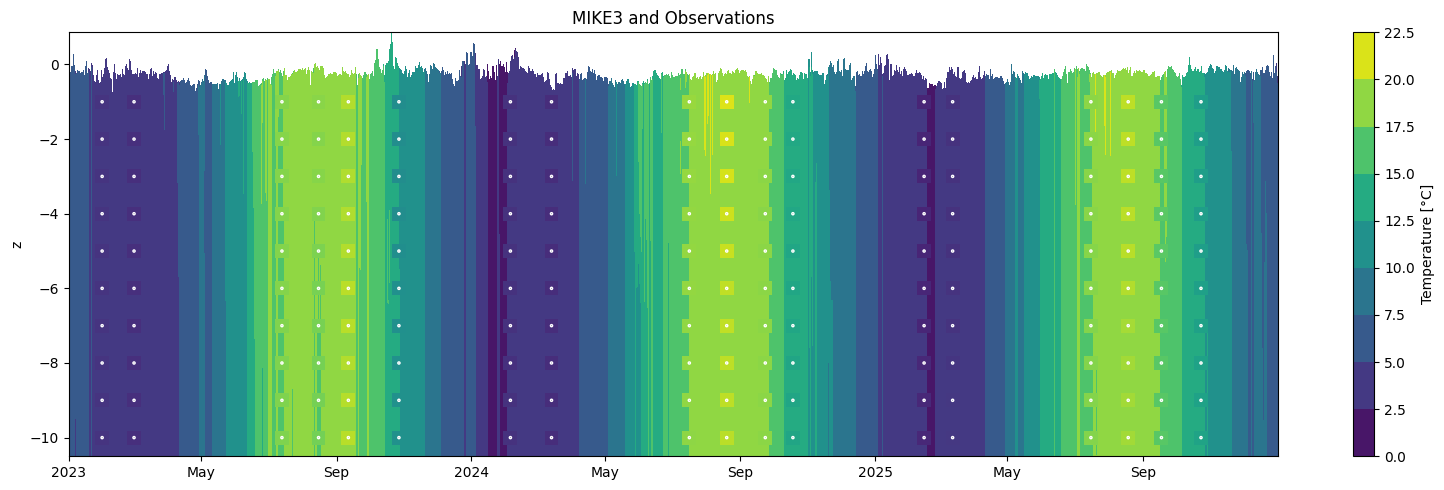

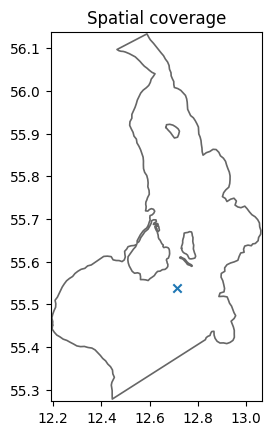

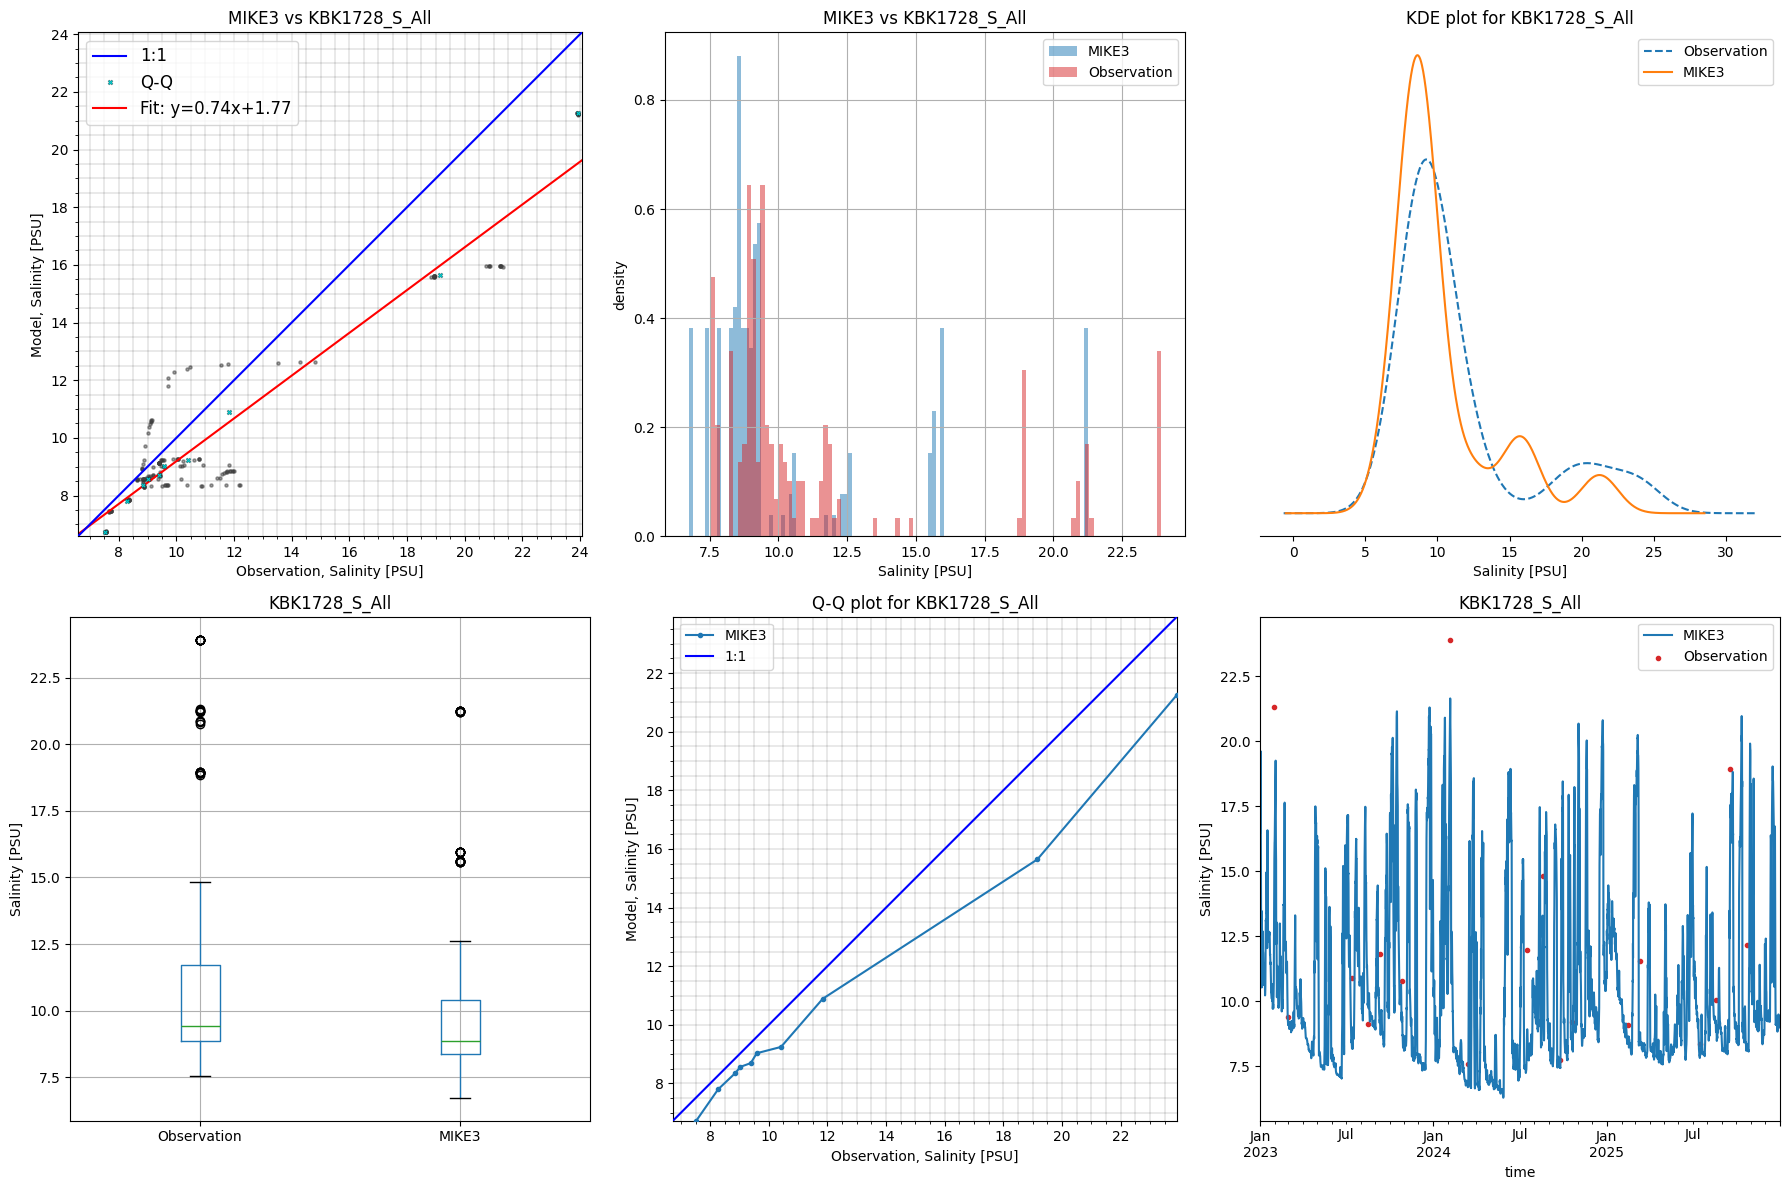

                bias      rmse     urmse       mae        cc        si  \
z                                                                        
(-25, -20]       NaN       NaN       NaN       NaN       NaN       NaN   
(-20, -15]       NaN       NaN       NaN       NaN       NaN       NaN   
(-15, -10] -1.806131  2.428464  1.623369  1.971575  0.947420  0.133613   
(-10, -5]  -1.297770  2.059073  1.598616  1.537628  0.953975  0.137521   
(-5, 0]    -0.894508  1.815661  1.580025  1.223341  0.959347  0.142353   

                  r2     n  
z                           
(-25, -20]       NaN   NaN  
(-20, -15]       NaN   NaN  
(-15, -10]  0.716300  18.0  
(-10, -5]   0.801575  90.0  
(-5, 0]     0.849603  72.0  


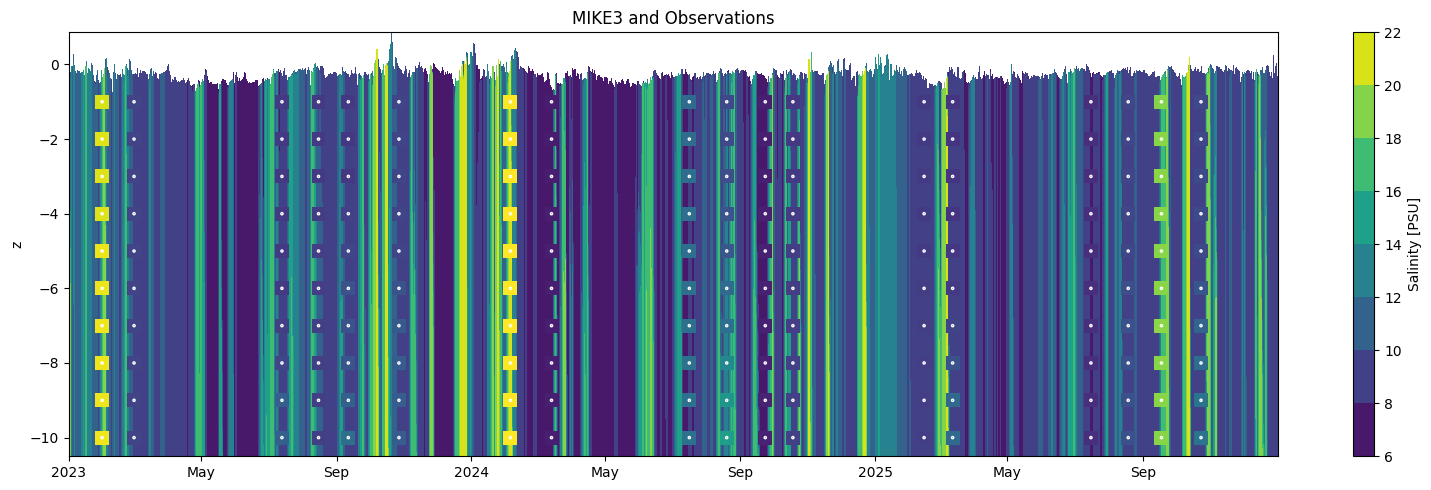

In [10]:
validate_ts_station(station_name, xpos, ypos, z_ts=-10)

The model captures temperature very well, and compared to the other two in-situ stations, the salinity here is captured relatively well. 

# Currents

Load data for validating the current velocity predictions.

In [11]:
# Only validate over the stations that have current (u/v) profile data
uv_stations = ["Flinten7", "Flinten16"]
stations = pd.read_csv("../observations/stations.csv").set_index("Station", drop=False).loc[uv_stations]
stations

,Station,Longitude,Latitude,Longitude_original,Latitude_original,crs
Station,,,,,,
Flinten7,Flinten7,12.8445,55.5894,NaN,NaN,EPSG:4326
Flinten16,Flinten16,12.8095,55.5610,NaN,NaN,EPSG:4326


In [12]:
ts_plot = slice("2025-01-01", "2025-04-30")

In [13]:
def validate_uv_station(station_name, xpos, ypos, z_ts=-4):
    quants = ['u', 'v']
    names = {'u': 'U velocity', 'v': 'V velocity'}
    units = {'u': 'm/s', 'v': 'm/s'}

    for q in quants:
        vo = ms.VerticalObservation(
            f"{obs_fldr}{station_name}_u_v.dfs0",
            item=q,
            z_item="z",
            x=xpos,
            y=ypos,
            quantity=ms.Quantity(names[q], units[q]),
        )
        mr = ms.DfsuModelResult(f"{mr_fldr}{mr_fn}", item=names[q], name="MIKE3")
        ax = ms.plotting.spatial_overview(vo, mr)
        cmp = ms.match(vo, mr)
        cmp.skill()

        fig, ax = plt.subplots(2, 3, figsize=(18, 12))
        _ = cmp.plot(ax=ax[0,0])
        _ = cmp.plot.hist(ax=ax[0,1])
        _ = cmp.plot.kde(ax=ax[0,2])
        _ = cmp.plot.box(ax=ax[1,0])
        _ = cmp.plot.qq(ax=ax[1,1])
        _ = cmp.sel(z=z_ts, time=ts_plot).plot.timeseries(ax=ax[1,2])
        plt.tight_layout()
        if save_png: plt.savefig(f"../figures/{station_name}_{q}_comparison.png", dpi=300, bbox_inches='tight')
        plt.show()

        sk = cmp.vertical.skill(bins=[-6, -4, -2, 0])
        print(sk.to_dataframe())


## Flinten 7

In [14]:
station_name = "Flinten7"
xpos = stations.loc[stations['Station'] == station_name, 'Longitude'].values[0]
ypos = stations.loc[stations['Station'] == station_name, 'Latitude'].values[0]

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(


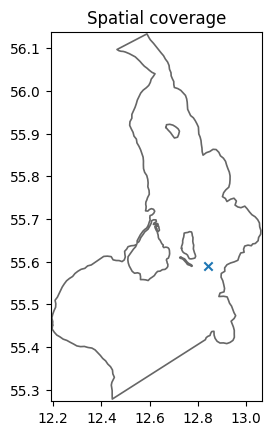

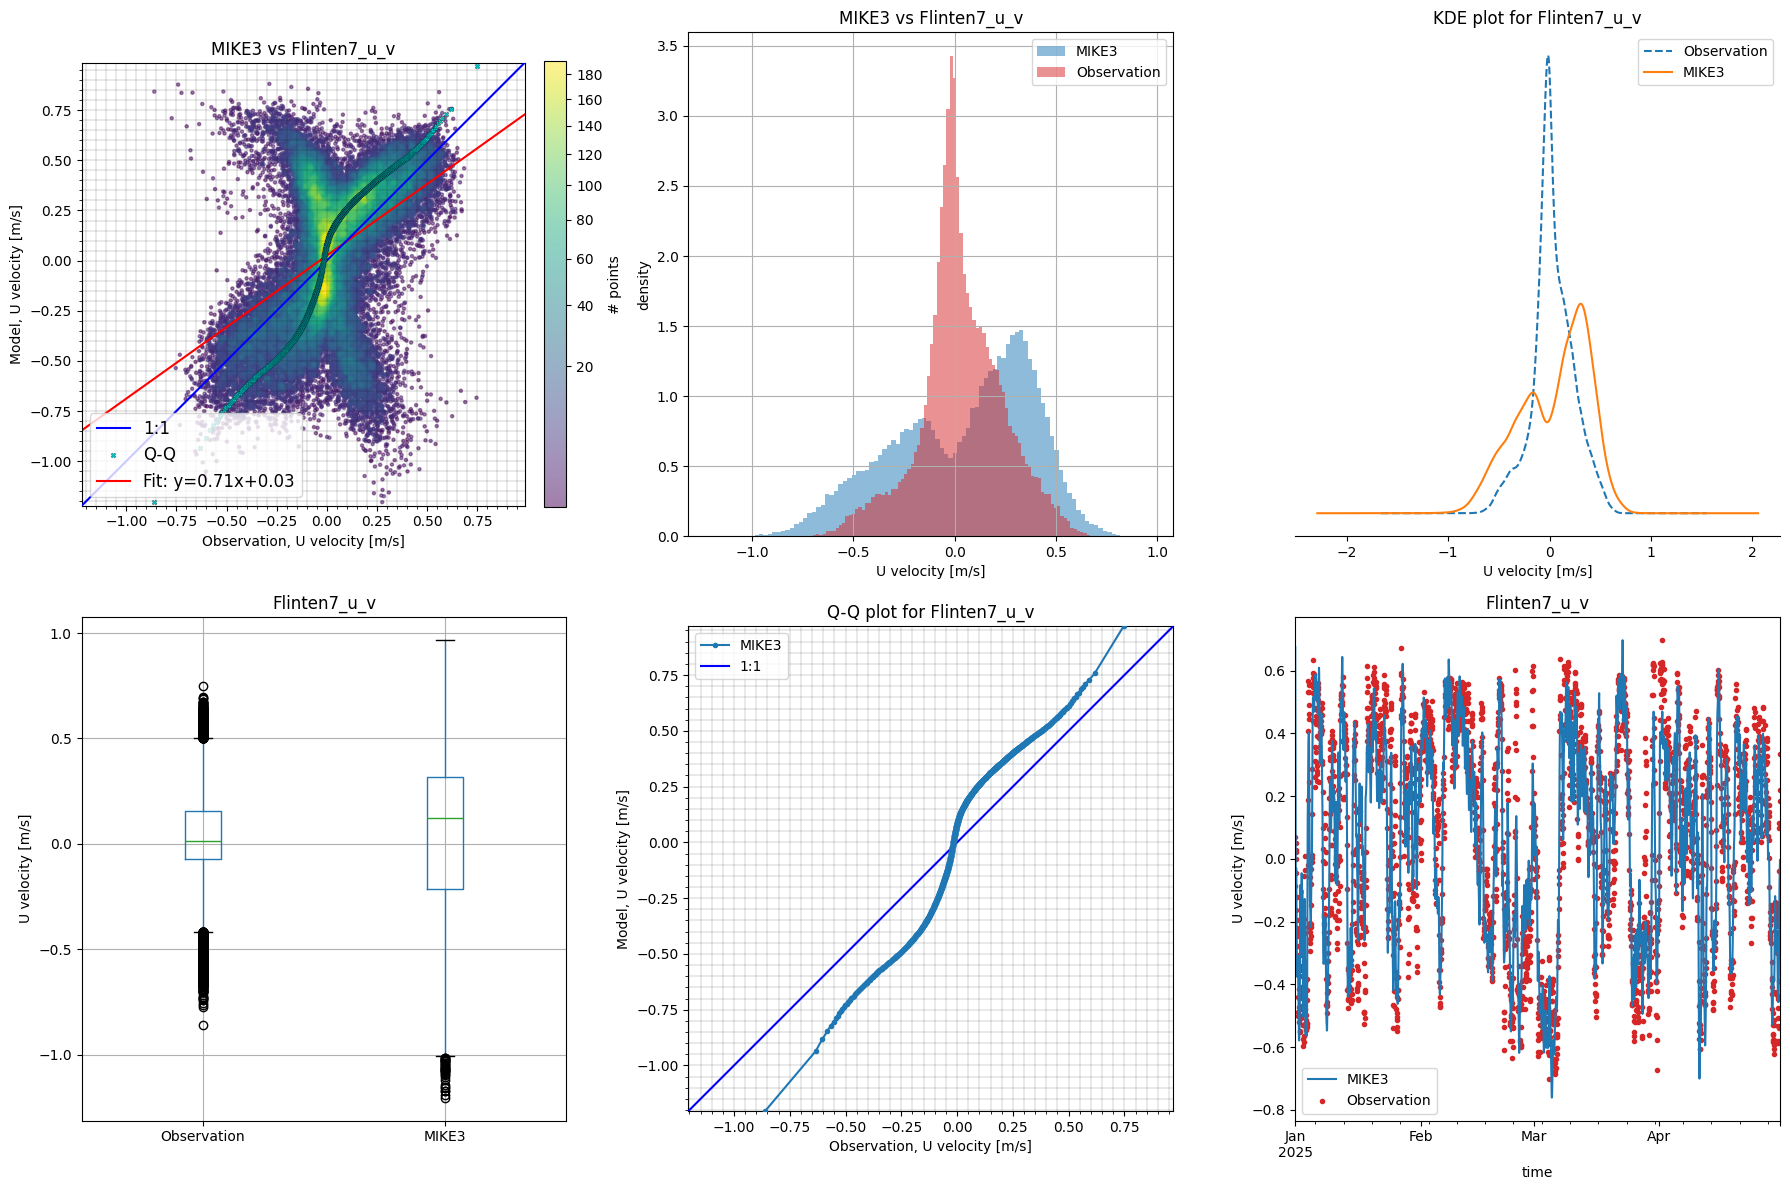

              bias      rmse     urmse       mae        cc        si  \
z                                                                      
(-6, -4]  0.016961  0.330479  0.330044  0.239625  0.412259  1.744248   
(-4, -2]  0.017810  0.376838  0.376417  0.282616  0.258408  2.376632   
(-2, 0]   0.527564  0.737797  0.515772  0.626999 -0.603230  2.094338   

                r2      n  
z                          
(-6, -4] -0.770275  25590  
(-4, -2] -2.344320  25762  
(-2, 0]  -6.096987    762  


c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(


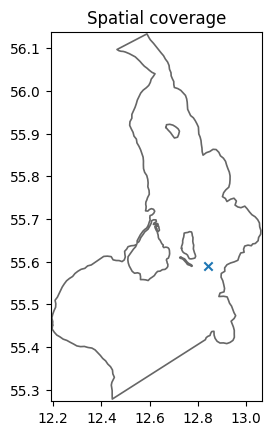

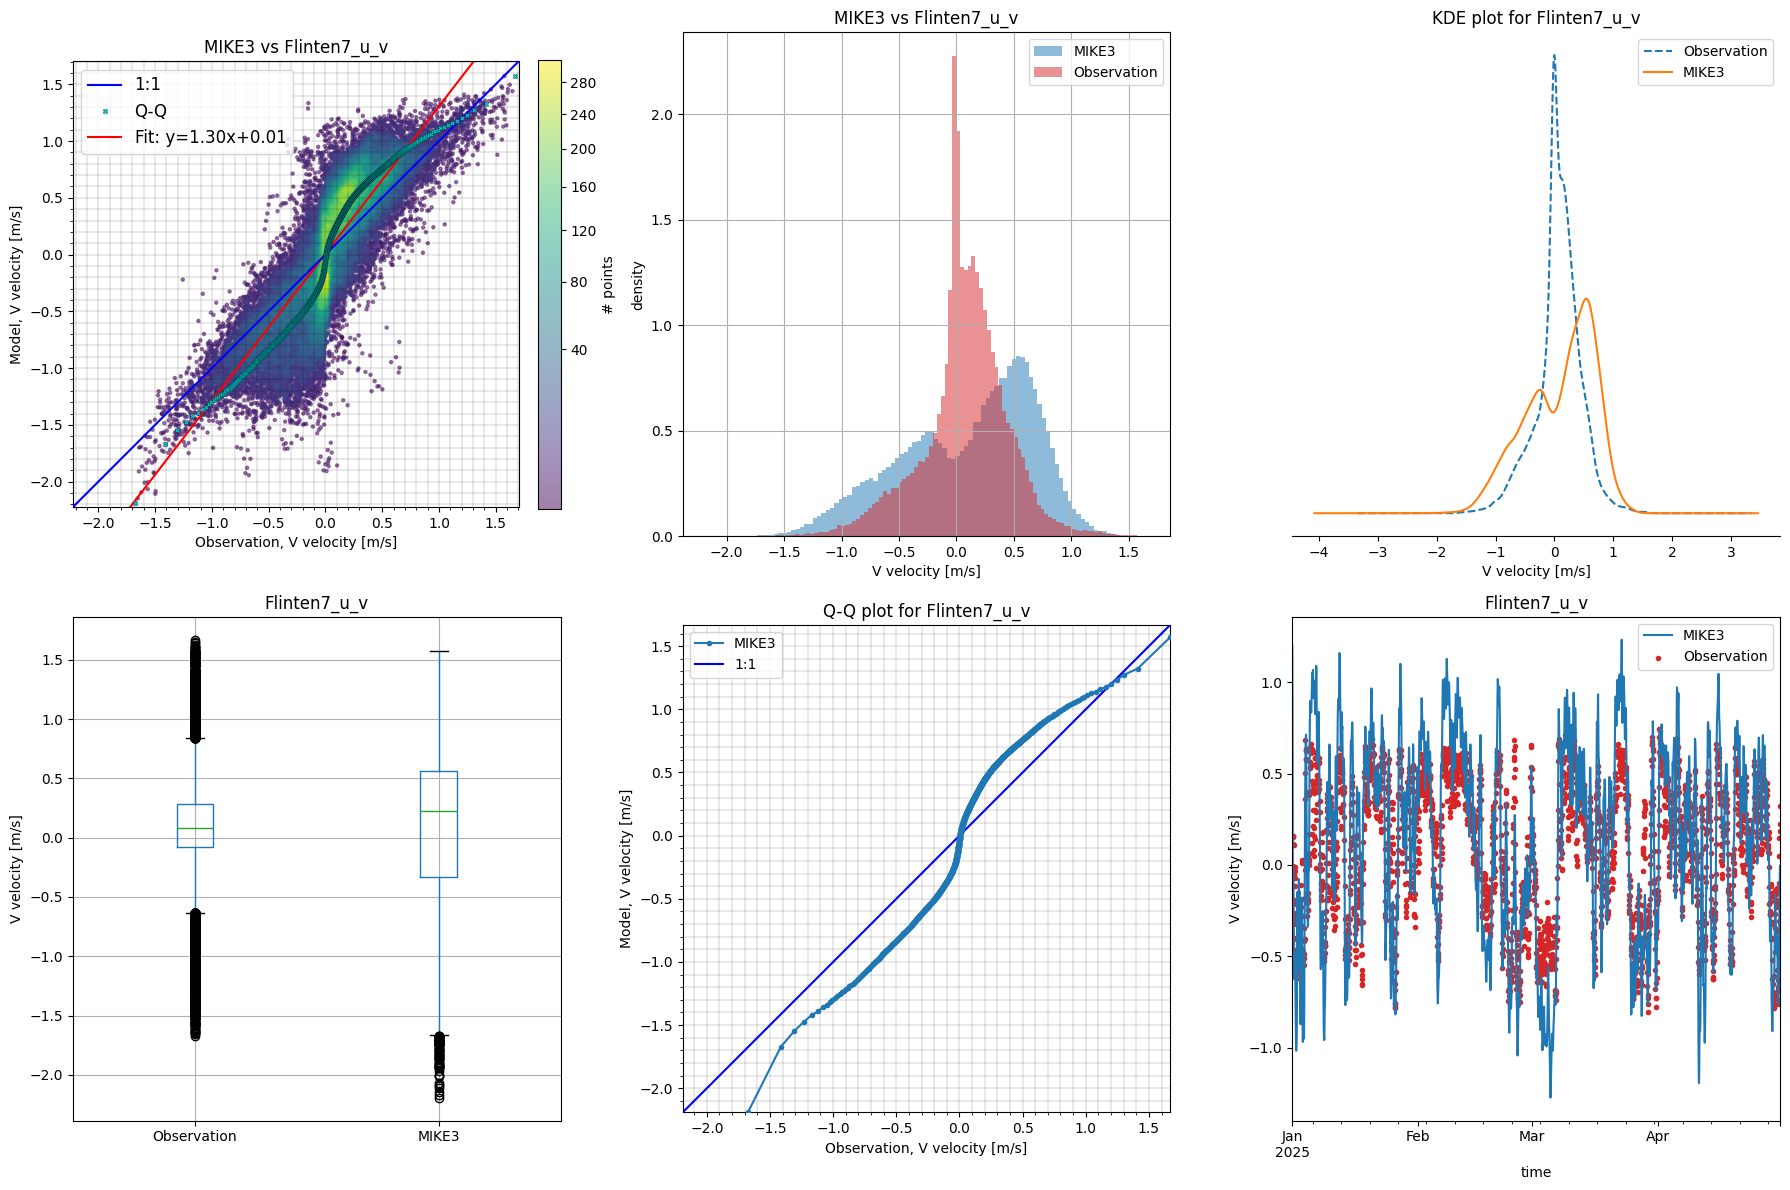

              bias      rmse     urmse       mae        cc        si  \
z                                                                      
(-6, -4]  0.017928  0.238340  0.237665  0.183335  0.918727  0.589125   
(-4, -2]  0.031014  0.361608  0.360276  0.289323  0.840674  1.171531   
(-2, 0]   0.242150  0.425367  0.349714  0.342334  0.768940  0.634973   

                r2      n  
z                          
(-6, -4]  0.749211  25590  
(-4, -2]  0.182473  25762  
(-2, 0]   0.321931    762  


In [15]:
validate_uv_station(station_name, xpos, ypos)

The model is challenged by modelling the current velocities, which is e.g. seen by the bimodal distribution. We remind the user that the current model setup has not been calibrated to full capacity, and should therefore only be used for educational, benchmarking, and research purposes only, NOT operational setups.

## Flinten 16

In [16]:
station_name = "Flinten16"
xpos = stations.loc[stations['Station'] == station_name, 'Longitude'].values[0]
ypos = stations.loc[stations['Station'] == station_name, 'Latitude'].values[0]

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(


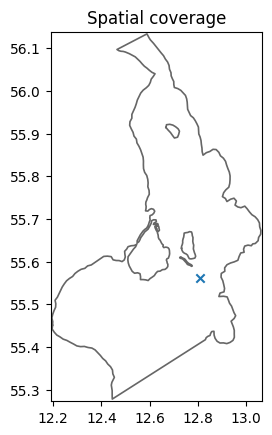

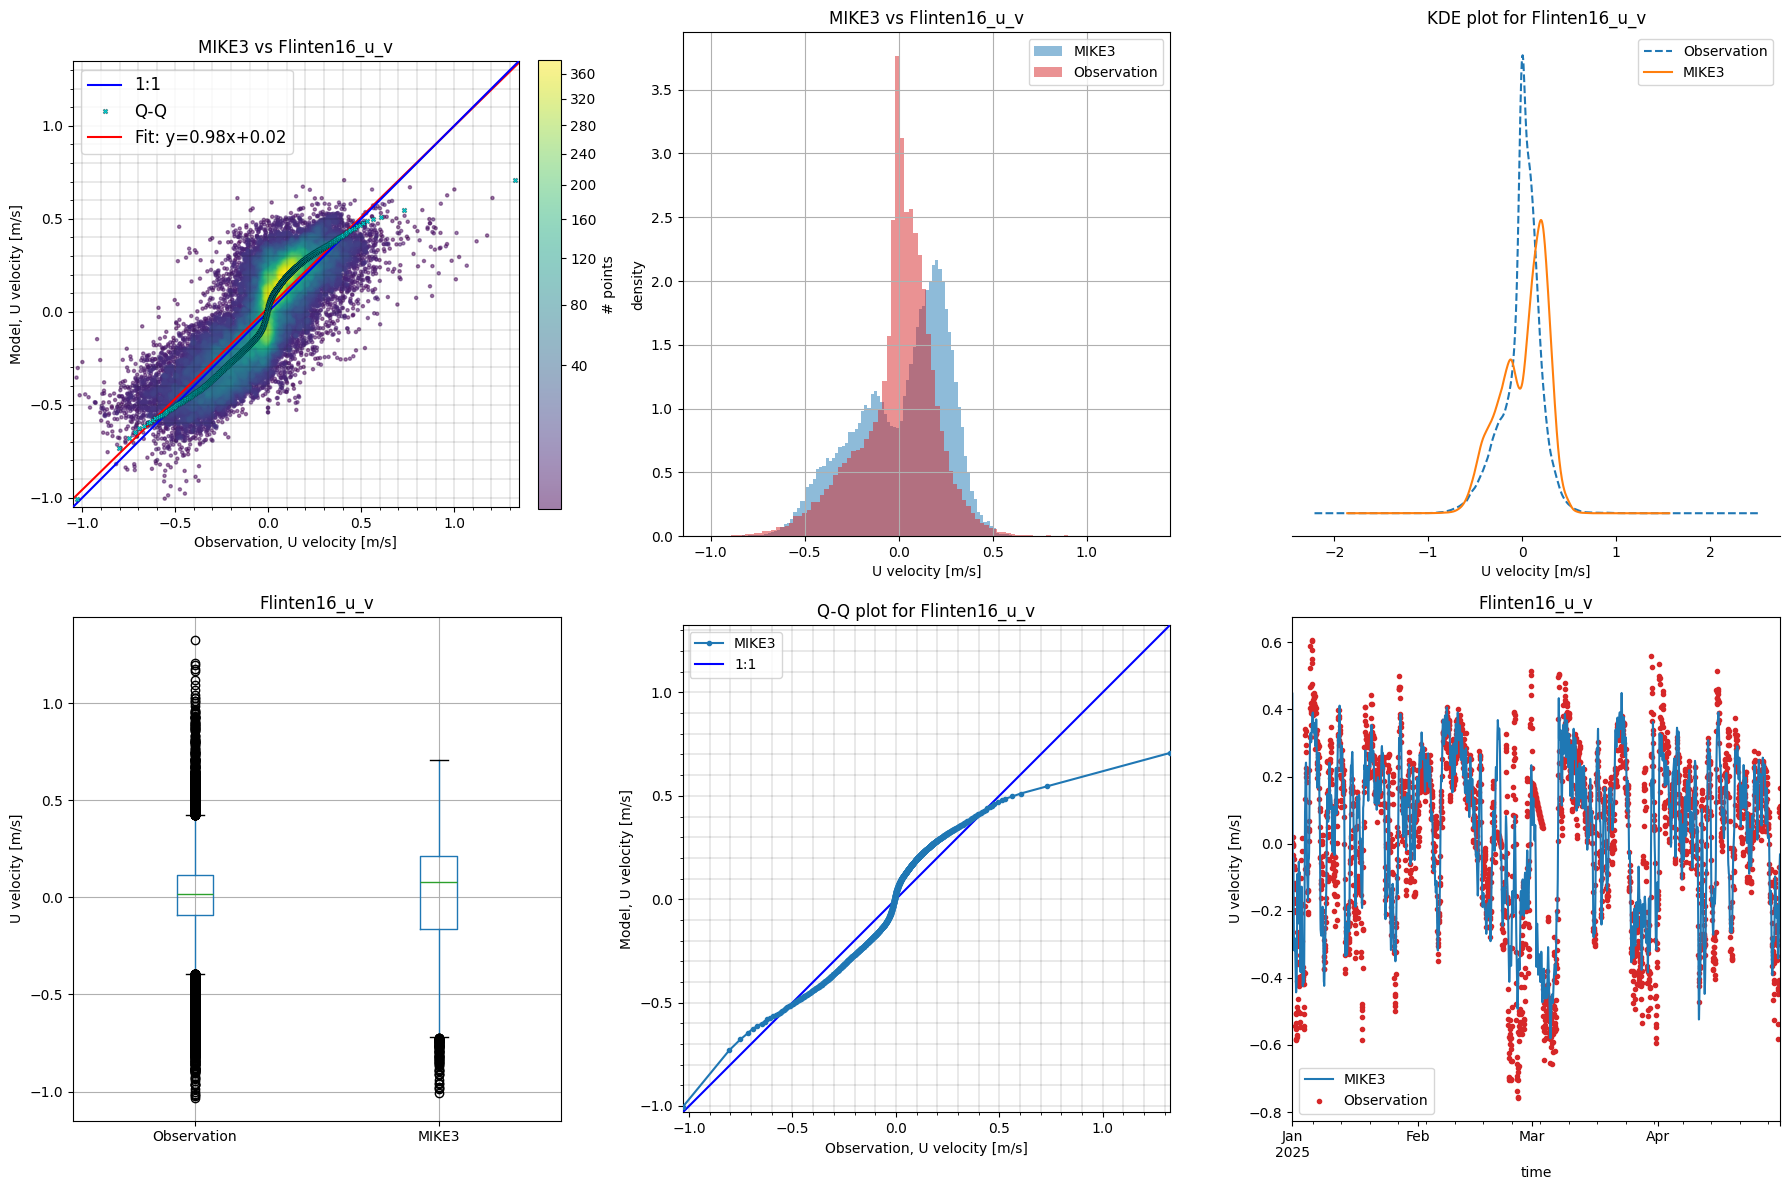

              bias      rmse     urmse       mae        cc        si  \
z                                                                      
(-6, -4]  0.015587  0.116000  0.114948  0.089763  0.887576  0.591809   
(-4, -2]  0.025233  0.160466  0.158470  0.129508  0.813273  0.910317   
(-2, 0]   0.143787  0.348695  0.317669  0.302125  0.217266  1.359046   

                r2      n  
z                          
(-6, -4]  0.762461  25913  
(-4, -2]  0.516433  26013  
(-2, 0]  -0.341162   1247  


c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(


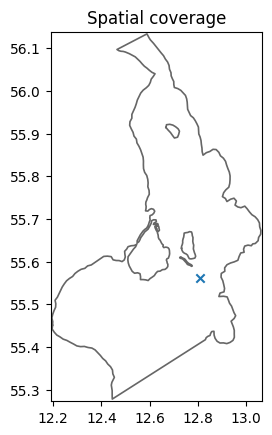

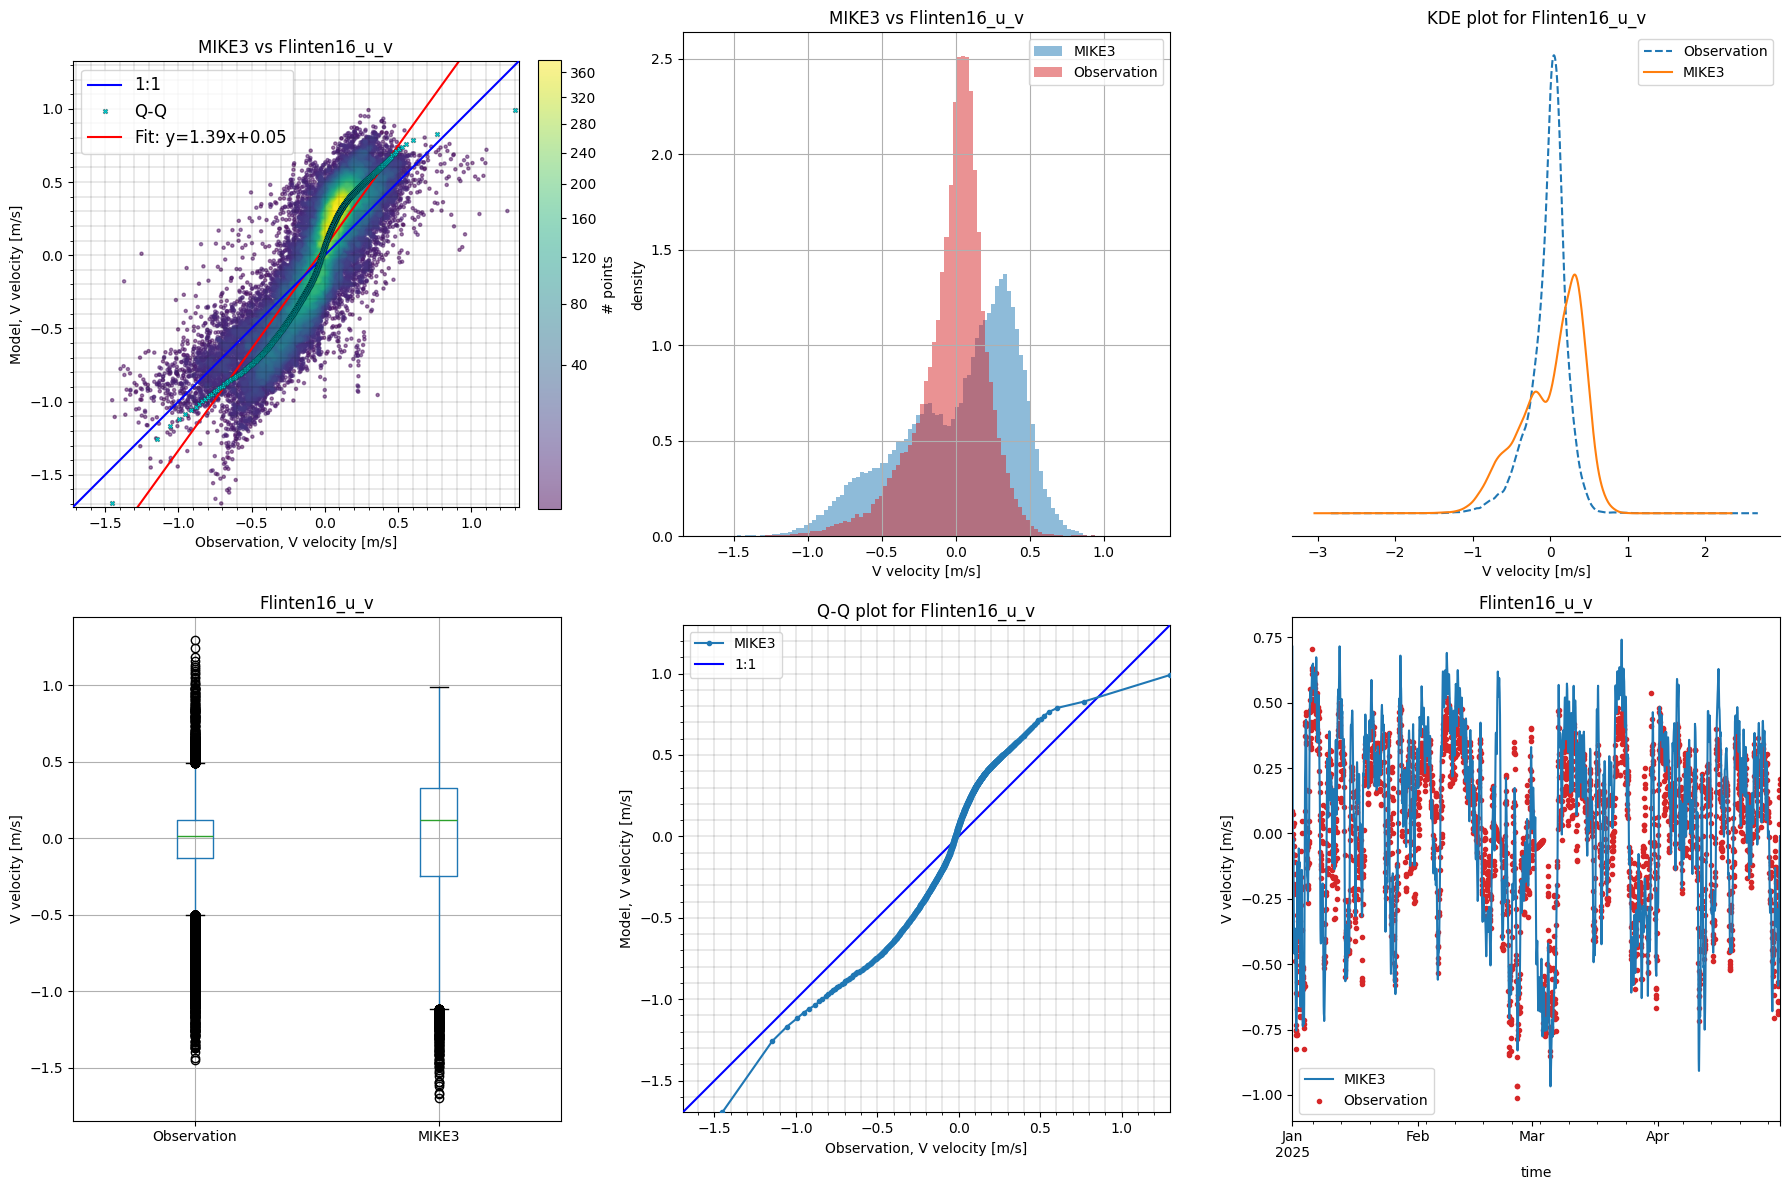

              bias      rmse     urmse       mae        cc        si  \
z                                                                      
(-6, -4]  0.040918  0.211402  0.207405  0.172270  0.878544  1.046515   
(-4, -2]  0.050710  0.254497  0.249394  0.213001  0.834388  1.285170   
(-2, 0]   0.346339  0.435299  0.263694  0.388407  0.596099  1.162710   

                r2      n  
z                          
(-6, -4]  0.349064  25913  
(-4, -2]  0.119402  26013  
(-2, 0]  -1.111592   1247  


In [17]:
validate_uv_station(station_name, xpos, ypos)

The model is challenged by modelling the current velocities, which is e.g. seen by the bimodal distribution. We remind the user that the current model setup has not been calibrated to full capacity, and should therefore only be used for educational, benchmarking, and research purposes only, NOT operational setups.